# Simulation

The model follows one order from payment to release or refund. It compares the two bussiness structures between Xianyu and Carousell Hong Kong on three things:

1. how long the platform holds the buyer's money;
2. whether the buyer can still recover money after a problem;
3. how much waiting the rule imposes on the seller.

The simulation is illustrative: the parameters are assumptions, not measurements of either platform. The point is to make the trade-off visible and to produce reproducible numbers for the report.

In [1]:
import random
import statistics
from dataclasses import dataclass, replace
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

## 1. Model parameters

- A **Channel** is a delivery route with its own dispute window. 
- A **Platform** has an automatic-completion clock that starts either from shipment (Xianyu) or from delivery (Carousell).

| Parameter | Default | What it means | If increased / changed |
|---|---:|---|---|
| `auto_from` | Xianyu: shipment<br>Carousell: delivery | Which event starts the automatic-completion clock. | Starting from shipment gives the buyer less time than starting from delivery. |
| window length | Xianyu: 10 days<br>Carousell: 4 / 2 / 5 / 9 days | Time until automatic completion; also the dispute window. | Longer → more claims captured, but sellers wait longer; recovery saturates once all claims fit. |
| route mix | Xianyu: 100% parcel<br>Carousell: 35% official / 35% custom tracked / 15% untracked / 15% meet-up | Probability of each delivery route. | More short-window routes → lower recovery, shorter seller wait. |
| `decision_days` | Xianyu: 3 days<br>Carousell: 5 days | Time from a valid dispute to the platform decision. | Longer → more seller waiting during disputes. |

In [2]:
@dataclass(frozen=True)
class Channel:
    name: str
    probability: float
    window_days: float


@dataclass(frozen=True)
class Platform:
    name: str
    auto_from: str          # "shipment" or "delivery"
    decision_days: float
    channels: tuple

# "shipment" means the clock starts when the seller ships the item (Xianyu)
# "delivery" means the clock starts when the buyer receives the item (Carousell HK)

XIANYU = Platform(
    name="Xianyu",
    auto_from="shipment",
    decision_days=3.0,
    channels=(Channel("parcel delivery", 1.00, 10.0),),
)

CAROUSELL = Platform(
    name="Carousell HK",
    auto_from="delivery",
    decision_days=5.0,
    channels=(
        Channel("official delivery", 0.35, 4.0),
        Channel("custom tracked", 0.35, 2.0),
        Channel("untracked", 0.15, 5.0),
        Channel("meet-up", 0.15, 9.0),
    ),
)

PLATFORMS = (XIANYU, CAROUSELL)


@dataclass
class SimParams:
    n: int = 20_000
    seed: int = 42
    off_platform_prob: float = 0.15
    problem_rate: float = 0.12
    non_receipt_share: float = 0.25
    claim_rate_on: float = 0.70
    claim_rate_off: float = 0.15
    confirm_prob: float = 0.70
    partial_refund_prob: float = 0.30
    snad_delay_max: float = 3.5
    nonreceipt_delay_max: float = 1.5
    price_mu: float = 5.0       # median price ~ HK$148
    price_sigma: float = 0.8
    max_price: float = 5_000.0


params = SimParams(n=20_000, seed=42)
params

SimParams(n=20000, seed=42, off_platform_prob=0.15, problem_rate=0.12, non_receipt_share=0.25, claim_rate_on=0.7, claim_rate_off=0.15, confirm_prob=0.7, partial_refund_prob=0.3, snad_delay_max=3.5, nonreceipt_delay_max=1.5, price_mu=5.0, price_sigma=0.8, max_price=5000.0)

### Simulation Parameters

| Group | Parameter | Default | What it means | If increased / changed |
|---|---|---:|---|---|
| Sample | `n` | 20,000 | Orders simulated **per platform** (40,000 rows in total). | More stable estimates, longer runtime. |
| Sample | `seed` | 42 | Random seed. Same seed + same parameters = identical results. | Different random sample; use other numbers to test stability. |
| Payment | `off_platform_prob` | 0.15 | Probability that the buyer pays outside the official order (direct transfer, not checkout). | More orders with no platform-held balance → lower buyer recovery, higher average loss. |
| Problem | `problem_rate` | 0.12 | Probability that an order has a problem: lost parcel or significantly not as described (SNAD). | More problem orders → higher average loss, more disputes. |
| Problem | `non_receipt_share` | 0.25 | Among problem orders, the share that are non-receipt rather than SNAD. | More non-receipt cases; these are always fully refunded if the claim is valid, so recovery tends to rise. |
| Problem | `snad_delay_max` | 3.5 days | Maximum delay after delivery before the buyer notices and reports a SNAD problem; actual delay is uniform from 0 to this value. | Slower claims → more claims fall outside short windows (e.g. Carousell's 2-day route) → lower recovery. |
| Problem | `nonreceipt_delay_max` | 1.5 days | Maximum delay after the expected delivery date before the buyer claims non-receipt. | Slower claims → more missed windows → lower recovery. |
| Behaviour | `claim_rate_on` | 0.70 | Given a problem, probability that an **on-platform** buyer actually files a dispute. | More claims → higher recovery and dispute rate; seller waits slightly longer. |
| Behaviour | `claim_rate_off` | 0.15 | Same for **off-platform** buyers. | In the current model, off-platform orders always get zero refund because the platform holds no money. It changes the recorded `claimed` flag, not the money outcomes. |
| Behaviour | `confirm_prob` | 0.70 | Probability that a delivered, undisputed order is confirmed by the buyer before automatic completion; confirmation occurs 0–2 days after delivery. | Earlier release → lower mean seller waiting time. |
| Remedy | `partial_refund_prob` | 0.30 | Among **upheld SNAD** claims, probability of a partial refund (20–60% of price) instead of a full refund/return. | More partial refunds → lower buyer recovery, but sellers keep more. Non-receipt always gets a full refund. |
| Price | `price_mu` | 5.0 | Mean of the **log** price. Median price = `exp(5.0) ≈ HK$148`. | Shifts all prices up; the recovery **rate** changes little, but average loss rises. |
| Price | `price_sigma` | 0.8 | Spread of the log price. Higher = more very cheap and very expensive items. | Wider price range; average loss more affected by expensive outliers. |
| Price | `max_price` | 5,000 | Hard cap on a single item price, in HKD. | Fewer extreme outliers above HK$5,000. |

## 2. Building the model for one simulated order

The buyer pays at day 0. 
- If the order is on-platform, the full price is held. A problem occurs with probability `problem_rate`; the buyer may claim within the window. A valid claim pauses automatic completion, and the platform decides using two evidence draws. 
- Off-platform orders release immediately and have no platform remedy.

The helper `summarize()` turns a list of orders into the metrics used in the report.

In [3]:
def simulate_order(platform: Platform, p: SimParams, rng: random.Random,
                   window_override: float = None) -> dict:
    price = min(p.max_price, max(20.0, rng.lognormvariate(p.price_mu, p.price_sigma)))
    channel = rng.choices(platform.channels, weights=[c.probability for c in platform.channels])[0]
    window = window_override if window_override is not None else channel.window_days

    off_platform = rng.random() < p.off_platform_prob
    has_problem = rng.random() < p.problem_rate
    non_receipt = has_problem and rng.random() < p.non_receipt_share

    ship_t = rng.uniform(1.0, 3.0)
    delivery_t = ship_t + rng.uniform(2.0, 5.0)
    expected_t = ship_t + 5.0

    if platform.auto_from == "shipment":
        auto_t = ship_t + window
    else:
        auto_t = (delivery_t if not non_receipt else expected_t) + window

    claimed = disputed = upheld = False
    refund = 0.0
    decision_t = dispute_t = None

    if has_problem:
        claim_rate = p.claim_rate_off if off_platform else p.claim_rate_on
        claimed = rng.random() < claim_rate

    if claimed and not off_platform:
        base = expected_t if non_receipt else delivery_t
        max_delay = p.nonreceipt_delay_max if non_receipt else p.snad_delay_max
        dispute_t = base + rng.uniform(0.0, max_delay)
        if dispute_t <= auto_t:
            disputed = True
            decision_t = dispute_t + platform.decision_days * rng.uniform(0.8, 1.3)

            buyer_evidence = rng.betavariate(2.0, 2.0)
            seller_evidence = rng.betavariate(2.0, 2.0)
            uphold_prob = min(0.90, max(0.10, 0.5 + 0.35 * (buyer_evidence - seller_evidence)))
            upheld = non_receipt or (rng.random() < uphold_prob)

            if upheld:
                if non_receipt or rng.random() >= p.partial_refund_prob:
                    refund = price
                else:
                    refund = price * rng.uniform(0.20, 0.60)

    if off_platform:
        release_t = 0.0
        refund = 0.0
        disputed = False
        decision_t = None
    elif disputed:
        release_t = decision_t
    else:
        if not non_receipt and rng.random() < p.confirm_prob:
            confirm_t = delivery_t + rng.uniform(0.0, 2.0)
            release_t = min(confirm_t, auto_t)
        else:
            release_t = auto_t

    held_days = max(0.0, release_t) if not off_platform else 0.0
    buyer_loss = (price - refund) if has_problem else 0.0

    return {
        "platform": platform.name,
        "channel": channel.name,
        "price": round(price, 2),
        "off_platform": off_platform,
        "problem": has_problem,
        "problem_type": ("non-receipt" if non_receipt else "SNAD") if has_problem else "",
        "claimed": claimed,
        "disputed": disputed,
        "upheld": upheld,
        "refund": round(refund, 2),
        "seller_received": round(price - refund, 2),
        "buyer_loss": round(buyer_loss, 2),
        "release_t": round(release_t, 2),
        "seller_wait_days": round(held_days, 2),
        "held_days": round(held_days, 2),
        "resolution_days": round(decision_t - dispute_t, 2) if disputed and decision_t else 0.0,
        "claim_window_days": window,
    }


def run_platform(platform: Platform, p: SimParams, window: float = None) -> list:
    rng = random.Random(p.seed)
    return [simulate_order(platform, p, rng, window) for _ in range(p.n)]


def p90(values: list) -> float:
    if not values:
        return 0.0
    s = sorted(values)
    return s[min(len(s) - 1, int(round(0.9 * (len(s) - 1))))]


def summarize(rows: list, platform_name: str, scenario: str = "baseline") -> dict:
    n = len(rows)
    problems = [r for r in rows if r["problem"]]
    disputes = [r for r in rows if r["disputed"]]
    on_platform = [r for r in rows if not r["off_platform"]]
    refunds = sum(r["refund"] for r in rows)
    losses = sum(r["price"] for r in problems)
    waits = [r["seller_wait_days"] for r in on_platform]
    return {
        "scenario": scenario,
        "platform": platform_name,
        "orders": n,
        "off_platform_share": round(sum(r["off_platform"] for r in rows) / n, 4),
        "problem_rate": round(len(problems) / n, 4),
        "claim_rate_given_problem": round(sum(r["claimed"] for r in problems) / len(problems), 4) if problems else 0.0,
        "dispute_rate": round(len(disputes) / n, 4),
        "uphold_rate": round(sum(r["upheld"] for r in disputes) / len(disputes), 4) if disputes else 0.0,
        "buyer_recovery_rate": round(refunds / losses, 4) if losses else 0.0,
        "avg_buyer_loss": round(sum(r["buyer_loss"] for r in rows) / n, 2),
        "mean_seller_wait_days": round(statistics.mean(waits), 2) if waits else 0.0,
        "p90_seller_wait_days": round(p90(waits), 2),
        "mean_held_days": round(statistics.mean([r["held_days"] for r in rows]), 2),
        "fund_days_per_order": round(sum(r["price"] * r["held_days"] for r in rows) / n, 2),
        "mean_resolution_days": round(statistics.mean([r["resolution_days"] for r in disputes]), 2) if disputes else 0.0,
    }

## 3. Baseline

Both platforms use the same behaviour parameters; only their rules differ. The key comparison is **buyer recovery** versus **seller waiting time**.

In [4]:
baseline_rows = []
baseline_orders = {}

for platform in PLATFORMS:
    rows = run_platform(platform, params)
    baseline_orders[platform.name] = rows
    baseline_rows.append(summarize(rows, platform.name))

baseline = pd.DataFrame(baseline_rows)
baseline[["platform", "orders", "buyer_recovery_rate", "avg_buyer_loss",
          "mean_seller_wait_days", "p90_seller_wait_days", "mean_held_days"]]

,platform,orders,buyer_recovery_rate,avg_buyer_loss,mean_seller_wait_days,p90_seller_wait_days,mean_held_days
0,Xianyu,20000,0.3350,16.83,8.39,12.34,7.12
1,Carousell HK,20000,0.3113,17.24,7.87,11.78,6.68


Buyer recovery is around **33.5%** for Xianyu and **31.1%** for Carousell HK. The platforms behave closely. Carousell's slightly lower recovery comes with a slightly shorter seller wait (7.87 vs 8.39 days). That is the trade-off the report is about: the rule does not remove risk, it moves it between the two sides.

## 4. Window experiment

Here every delivery route is forced to the same window, so the effect of the window itself is visible. The window is a policy variable, not a platform label.

In [5]:
window_rows = []

for platform, windows in ((XIANYU, [5, 10, 15, 20]), (CAROUSELL, [2, 4, 7, 10])):
    for w in windows:
        rows = run_platform(platform, params, window=w)
        result = summarize(rows, platform.name, f"{w} days")
        result["window_days"] = w
        window_rows.append(result)

windows = pd.DataFrame(window_rows)
windows[["platform", "window_days", "buyer_recovery_rate", "mean_seller_wait_days", "mean_held_days"]]

,platform,window_days,buyer_recovery_rate,mean_seller_wait_days,mean_held_days
0,Xianyu,5,0.0740,6.59,5.60
1,Xianyu,10,0.3350,8.39,7.12
2,Xianyu,15,0.3350,9.81,8.33
3,Xianyu,20,0.3350,11.23,9.53
4,Carousell HK,2,0.2575,7.13,6.06
5,Carousell HK,4,0.3350,7.87,6.68
6,Carousell HK,7,0.3350,8.72,7.40
7,Carousell HK,10,0.3350,9.58,8.13


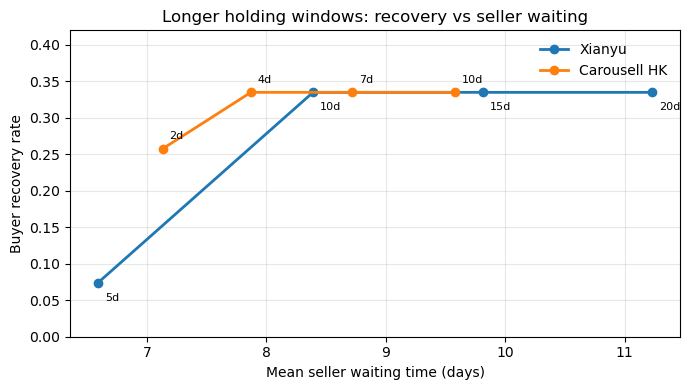

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))

offsets = {XIANYU: -13, CAROUSELL: 7}
for platform in PLATFORMS:
    sub = windows[windows["platform"] == platform.name]
    ax.plot(sub["mean_seller_wait_days"], sub["buyer_recovery_rate"],
            marker="o", linewidth=2, label=platform.name)
    for _, row in sub.iterrows():
        ax.annotate(f'{int(row["window_days"])}d',
                    (row["mean_seller_wait_days"], row["buyer_recovery_rate"]),
                    textcoords="offset points", xytext=(5, offsets[platform]),
                    fontsize=8, clip_on=True)

ax.set_xlabel("Mean seller waiting time (days)")
ax.set_ylabel("Buyer recovery rate")
ax.set_title("Longer holding windows: recovery vs seller waiting")
ax.set_ylim(0, 0.42)
ax.grid(alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**note:** Recovery rises until the window covers the typical claim delay, then flattens:

- Xianyu: 5 days → 7.4%; 10 days → 33.5%; 15 and 20 days add 1.4 and 2.8 days of seller waiting with **no** recovery gain.
- Carousell: 2 days → 25.8%; 4 days → 33.5%; 7 and 10 days only add waiting.

The result is conditional on the claim-delay assumption. If buyers are slower to notice problems, the saturation point moves later. The model shows the shape of the trade-off, not the correct policy.

## 5. Off-platform experiment

When payment leaves the order, the platform holds no balance and has no order link. The model therefore gives the buyer no platform remedy.

In [7]:
off_rows = []

for share in [0.0, 0.10, 0.25, 0.50]:
    p = replace(params, off_platform_prob=share)
    for platform in PLATFORMS:
        rows = run_platform(platform, p)
        result = summarize(rows, platform.name, f"{int(share * 100)}% off-platform")
        result["off_platform_share"] = share
        off_rows.append(result)

offplatform = pd.DataFrame(off_rows)
offplatform[["platform", "off_platform_share", "buyer_recovery_rate",
             "avg_buyer_loss", "mean_seller_wait_days"]]

,platform,off_platform_share,buyer_recovery_rate,avg_buyer_loss,mean_seller_wait_days
0,Xianyu,0.00,0.4058,15.17,8.40
1,Carousell HK,0.00,0.3671,16.11,7.88
2,Xianyu,0.10,0.3555,16.13,8.38
3,Carousell HK,0.10,0.3269,16.64,7.87
4,Xianyu,0.25,0.2878,17.79,8.37
5,Carousell HK,0.25,0.2677,18.22,7.83
6,Xianyu,0.50,0.2012,20.46,8.34
7,Carousell HK,0.50,0.1909,20.81,7.85


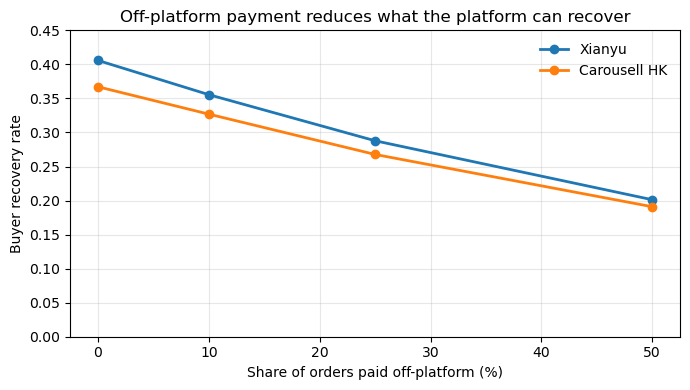

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))

for platform in PLATFORMS:
    sub = offplatform[offplatform["platform"] == platform.name]
    ax.plot(sub["off_platform_share"] * 100, sub["buyer_recovery_rate"],
            marker="o", linewidth=2, label=platform.name)

ax.set_xlabel("Share of orders paid off-platform (%)")
ax.set_ylabel("Buyer recovery rate")
ax.set_title("Off-platform payment reduces what the platform can recover")
ax.set_ylim(0, 0.45)
ax.grid(alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**note:** At 50% off-platform, recovery falls to about **20%** on both platforms, and average loss rises. The mechanism is mechanical: the platform cannot refund money it does not hold. The result supports the argument in Sections 3.4 and 4.4, but it is an illustration, not an estimate of a real policy change.

## 6. Save the results

In [9]:
out = Path("simulation_results")
out.mkdir(exist_ok=True)

baseline.to_csv(out / "baseline.csv", index=False)
windows.to_csv(out / "windows.csv", index=False)
offplatform.to_csv(out / "offplatform.csv", index=False)

print("Saved to", out.resolve())
sorted(p.name for p in out.glob("*.csv"))

Saved to /Users/ffb/Desktop/CUHK/ECLT 5720/Project/Code_part/ECLT_5720_Project/simulation_results


['baseline.csv', 'offplatform.csv', 'windows.csv']

## 7. Tuning the parameters (Sensitivity Check)

Change one parameter and rerun the baseline. 

- `claim_rate_on=0.3` or `0.9`: how much does buyer behaviour matter compared with the rule?
- `partial_refund_prob=0.1` or `0.5`: what happens to recovery when partial refunds are rarer?
- `problem_rate=0.05` or `0.25`: does the conclusion depend on how common problems are?

Keep the seed and `n` fixed when comparing runs.

### Remarks

- The parameters are illustrative; they are not calibrated to platform data.
- The decision rule is a simple evidence model, not a platform's actual process.
- There is one order and at most one dispute; appeals and chargebacks are excluded.
- The model compares rules, not fraud rates or platform quality.